# Example of the aitlas toolbox in the context of multi class image classification

## Import the required packages

In [ ]:
from aitlas.datasets import TenGeoPSARwvDataset
from aitlas.models import VisionTransformer
from aitlas.transforms import ResizeCenterCropFlipHVToTensor, ResizeCenterCropToTensor, ResizeRandomCropFlipHVToTensor
from aitlas.utils import image_loader
import numpy as np

## Load the dataset

In [ ]:
dataset_config = {
    "data_dir": "./data/TenGeoP-SARwv/GeoTIFF/",
    "csv_file": "./data/TenGeoP-SARwv/GeoTIFF/train.csv",
    "batch_size": 128,
    "shuffle": True,
    "num_workers": 4,
}
dataset = TenGeoPSARwvDataset(dataset_config)

## Show images from the dataset

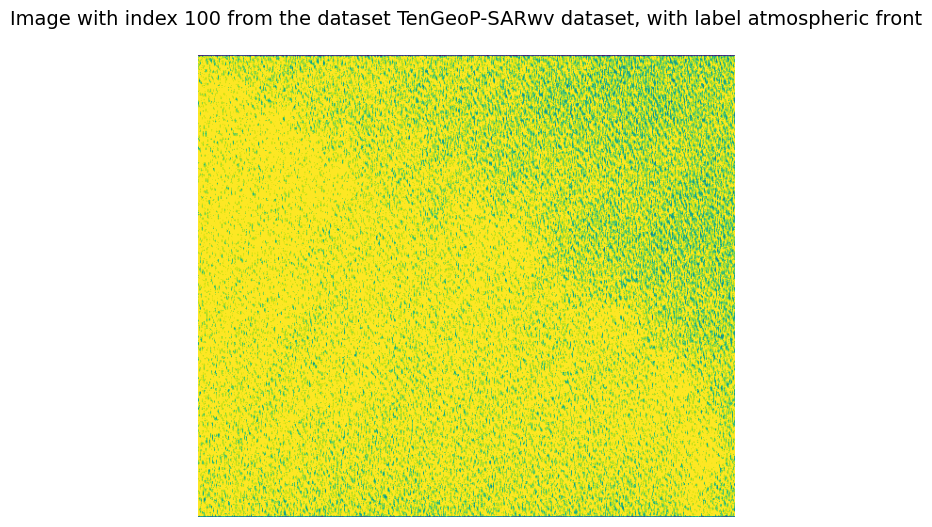

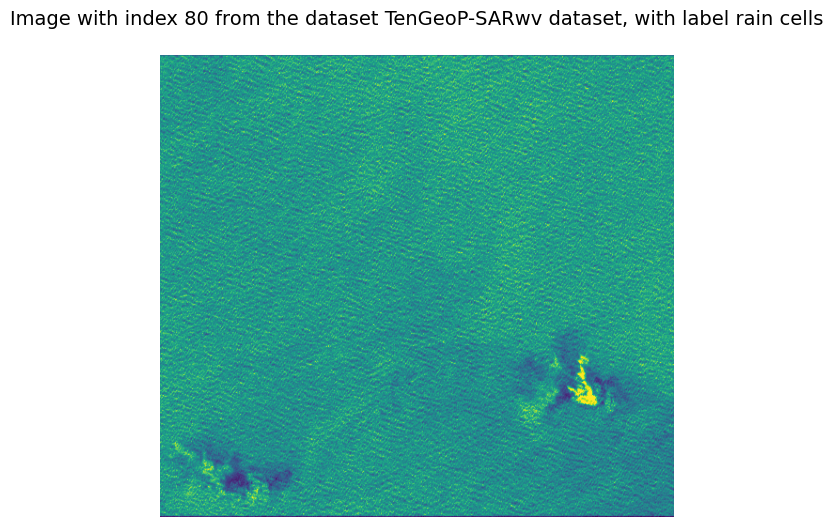

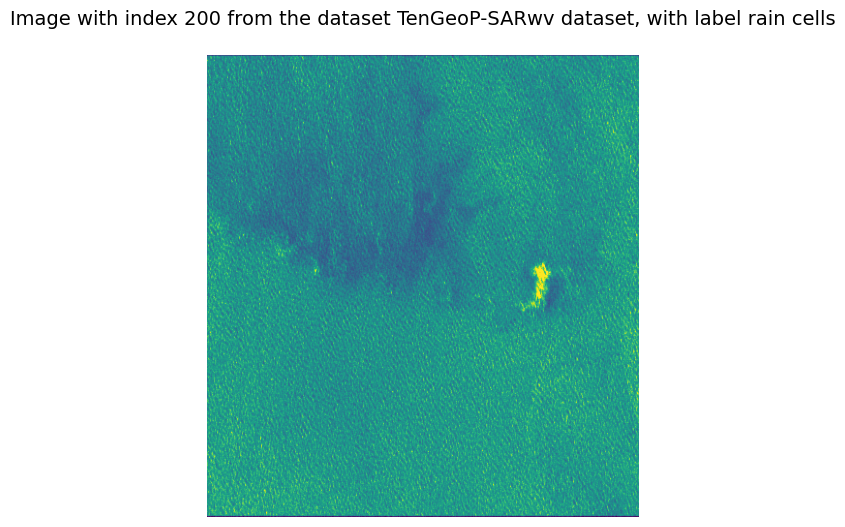

In [51]:
fig1 = dataset.show_image(100)
fig2 = dataset.show_image(80)
fig3 = dataset.show_image(200)

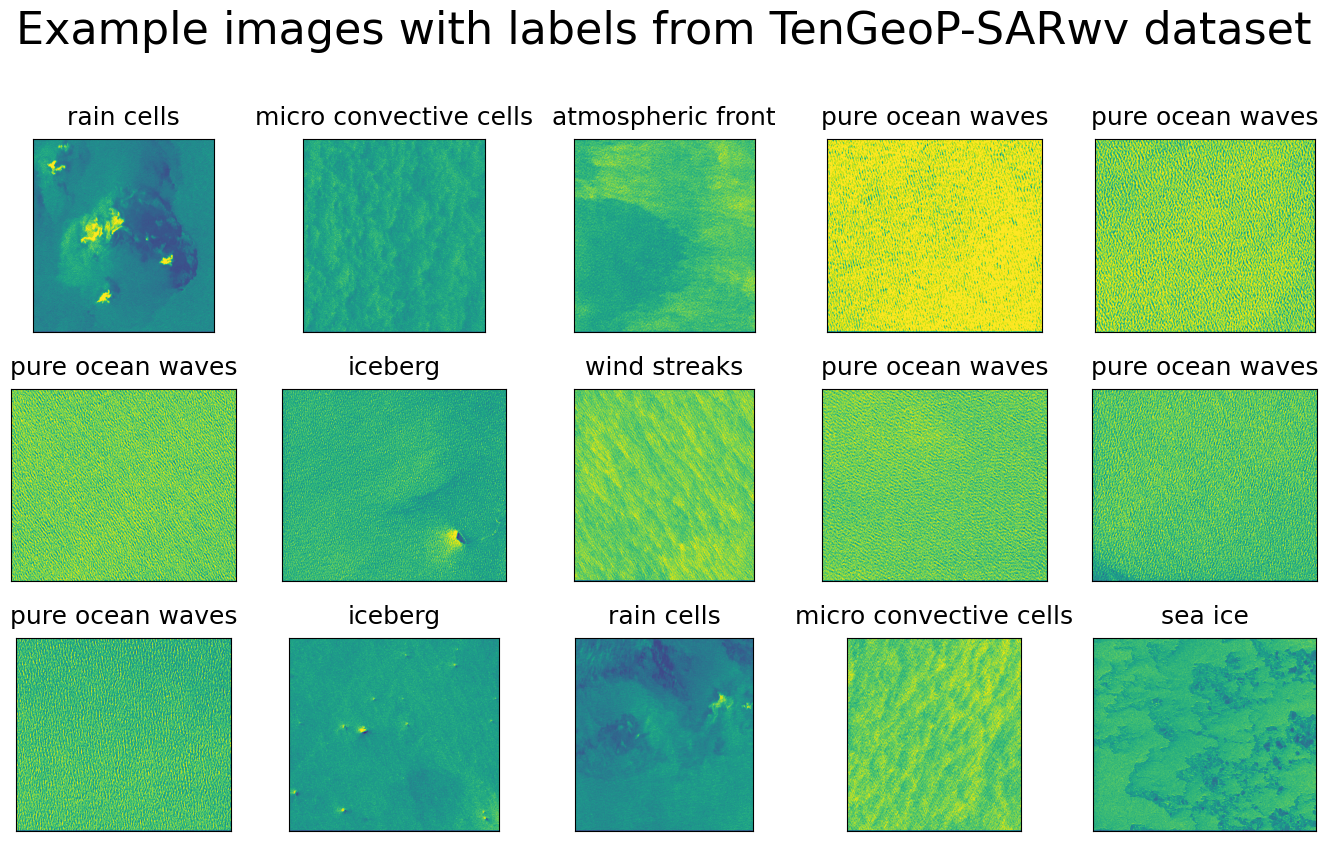

In [52]:
fig4 = dataset.show_batch(15)

## Inspect the data

In [21]:
dataset.show_samples()

,File name,Label
0,H/s1a-wv1-slc-vv-20160112t014732-20160112t0147...,micro convective cells
1,H/s1a-wv1-slc-vv-20161107t112702-20161107t1127...,micro convective cells
2,K/s1a-wv2-slc-vv-20161031t050021-20161031t0500...,sea ice
3,N/s1a-wv2-slc-vv-20160514t072327-20160514t0723...,atmospheric front
4,G/s1a-wv2-slc-vv-20160111t125623-20160111t1256...,wind streaks
5,H/s1a-wv2-slc-vv-20161224t101821-20161224t1018...,micro convective cells
6,H/s1a-wv2-slc-vv-20160203t202040-20160203t2020...,micro convective cells
7,L/s1a-wv2-slc-vv-20160219t080321-20160219t0803...,iceberg
8,G/s1a-wv2-slc-vv-20160318t011042-20160318t0110...,wind streaks
9,M/s1a-wv1-slc-vv-20161117t152028-20161117t1520...,low wind area


In [25]:
dataset.data_distribution_table()

,Label,Count
0,atmospheric front,3272
1,biological slicks,3805
2,iceberg,1583
3,low wind area,1712
4,micro convective cells,3652
5,oceanic front,943
6,pure ocean waves,3942
7,rain cells,3767
8,sea ice,3504
9,wind streaks,3863


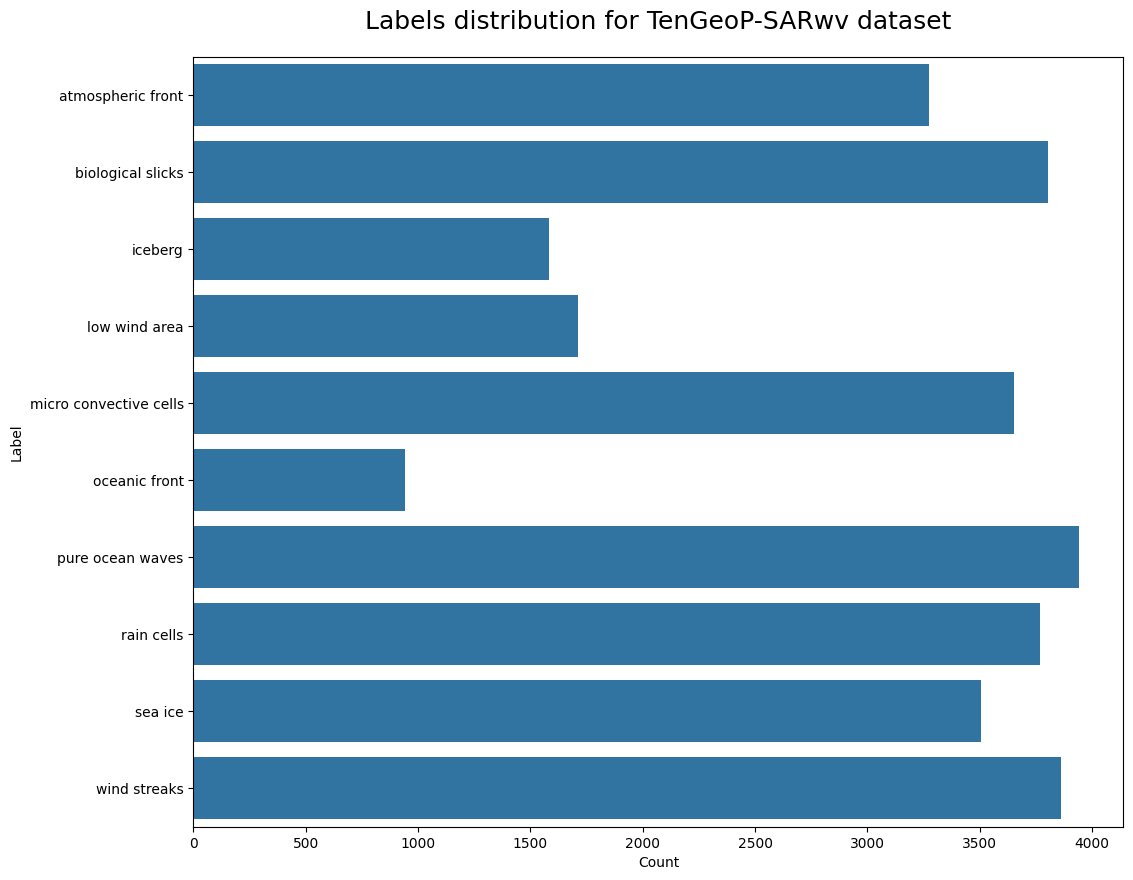

In [26]:
fig = dataset.data_distribution_barchart()

## Load train and validation splits

In [ ]:
train_dataset_config = {
    "batch_size": 32,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/TenGeoP-SARwv/GeoTIFF/",
    "csv_file": "./data/TenGeoP-SARwv/GeoTIFF/train.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

train_dataset = TenGeoPSARwvDataset(train_dataset_config)
train_dataset.transform = ResizeRandomCropFlipHVToTensor() 

validation_dataset_config = {
    "batch_size": 32,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/TenGeoP-SARwv/GeoTIFF/",
    "csv_file": "./data/TenGeoP-SARwv/GeoTIFF/val.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

validation_dataset = TenGeoPSARwvDataset(validation_dataset_config)
len(train_dataset), len(validation_dataset)

(30043, 3755)

## Setup and create the model for training

In [ ]:
epochs = 10
model_directory = "./data/experiments/TenGeoP-SARwv/"
model_config = {
    "num_classes": 10, 
    "learning_rate": 0.0001,
    "pretrained": True,
    "metrics": ["accuracy", "precision", "recall", "f1_score"]
}
model = VisionTransformer(model_config)
model.prepare()

2025-05-20 10:21:49,149 INFO Loading pretrained weights from Hugging Face hub (timm/vit_base_patch16_224.augreg2_in21k_ft_in1k)
2025-05-20 10:21:49,526 INFO [timm/vit_base_patch16_224.augreg2_in21k_ft_in1k] Safe alternative available for 'pytorch_model.bin' (as 'model.safetensors'). Loading weights using safetensors.


## Training and validation

In [7]:
model.train_and_evaluate_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    val_dataset=validation_dataset,
    run_id='1',
)

2025-05-20 10:21:50,939 INFO Starting training.
training: 100%|██████████| 939/939 [08:17<00:00,  1.89it/s]
2025-05-20 10:30:08,198 INFO epoch: 1, time: 497, loss:  0.21417
testing on train set: 100%|██████████| 939/939 [03:04<00:00,  5.10it/s]
2025-05-20 10:33:15,219 INFO Accuracy:0.9642845255134308, Precision Micro:0.9642845255134308, Precision Macro:0.9634514618570318, Precision Weighted:0.964483605827235, Precision per Class:[0.97467402 0.96643394 0.96834213 0.98353691 0.94978766 0.98321479
 0.97003257 0.96327014 0.9218425  0.95337995], Recall Micro:0.9642845255134308, Recall Macro:0.9547188819893142, Recall Weighted:0.9642845255134307, Recall per Class:[0.98604769 0.93165933 0.95481928 0.98327582 0.99921156 0.98630137
 0.94061908 0.94976636 0.94804401 0.86744433], F1_score Micro:0.9642845255134302, F1_score Macro:0.9587337997000123, F1_score Weighted:0.9641550550681744, F1_score per Class:[0.98032787 0.94872809 0.96153316 0.98340635 0.97387295 0.98475566
 0.95509942 0.95647059 0.9

0.11211675697072655

## Test the model

In [ ]:

test_dataset_config = {
    "batch_size": 16,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/TenGeoP-SARwv/GeoTIFF/",
    "csv_file": "./data/TenGeoP-SARwv/GeoTIFF/test.csv",
    "transforms": ["aitlas.transforms.ResizeCenterCropToTensor"]
}

test_dataset = TenGeoPSARwvDataset(test_dataset_config)
model_path = "./data/experiments/TenGeoP-SARwv/checkpoint.pth.tar"
model.metrics = ["accuracy", "precision", "recall", "f1_score"]
model.running_metrics.reset()
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

2025-05-20 12:03:14,836 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/TenGeoP-SARwv/checkpoint.pth.tar
2025-05-20 12:03:15,801 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/TenGeoP-SARwv/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 235/235 [00:28<00:00,  8.36it/s]


[{'Accuracy': 0.9509986684420773},
 {'Precision Micro': 0.9509986684420773,
  'Precision Macro': 0.9518357599395492,
  'Precision Weighted': 0.9528454827820039,
  'Precision per Class': array([0.96887967, 0.96421053, 0.95887446, 0.87642586, 0.96929825,
         0.98387097, 0.96875   , 0.9832636 , 0.93853428, 0.90625   ])},
 {'Recall Micro': 0.9509986684420773,
  'Recall Macro': 0.9440027100816435,
  'Recall Weighted': 0.9509986684420773,
  'Recall per Class': array([0.98523207, 0.95218295, 0.96095445, 0.99139785, 0.9844098 ,
         0.84526559, 0.88995215, 0.96311475, 0.96829268, 0.89922481])},
 {'F1_score Micro': 0.9509986684420767,
  'F1_score Macro': 0.9468216172215076,
  'F1_score Weighted': 0.950732155153466,
  'F1_score per Class': array([0.97698745, 0.958159  , 0.95991333, 0.93037336, 0.97679558,
         0.90931677, 0.9276808 , 0.97308489, 0.95318127, 0.90272374])}]

## Predictions

2025-05-20 12:03:43,939 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/TenGeoP-SARwv/checkpoint.pth.tar
2025-05-20 12:03:44,700 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/TenGeoP-SARwv/checkpoint.pth.tar at epoch 11


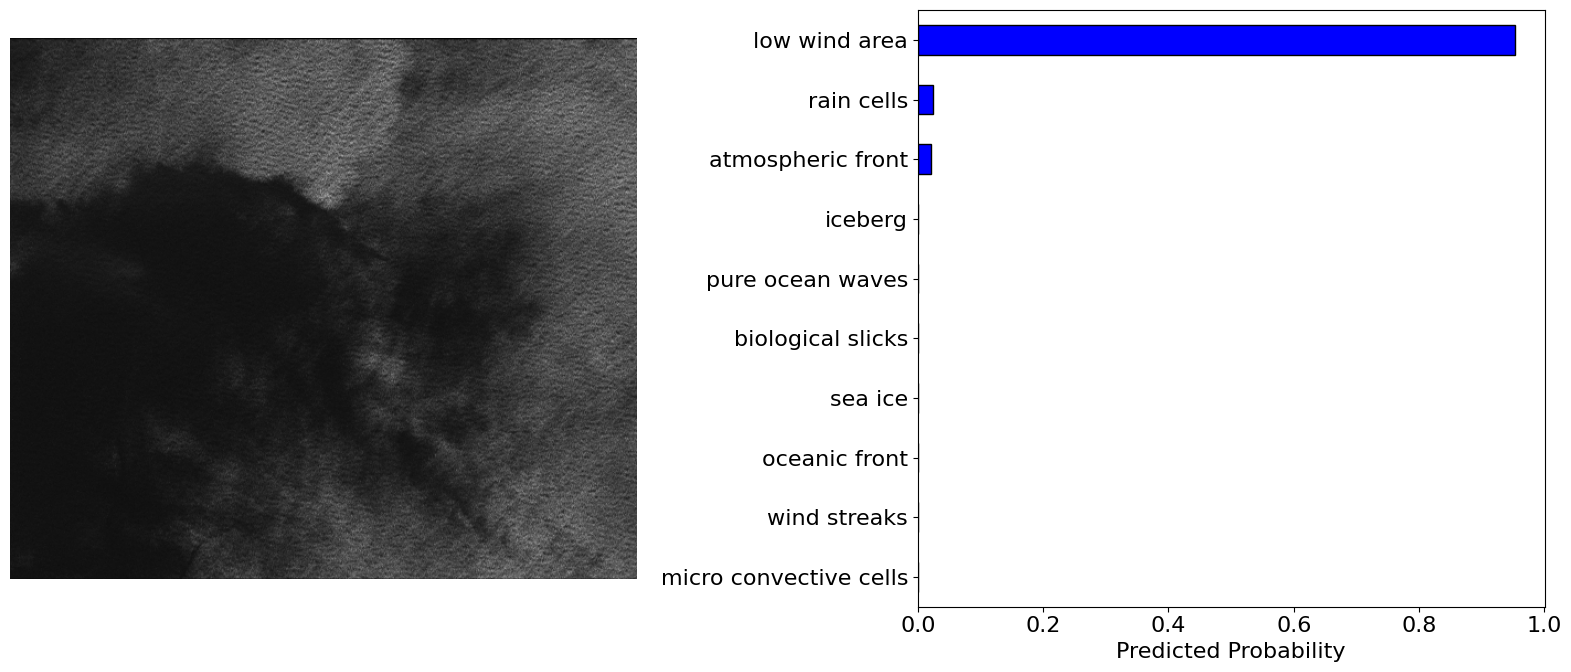

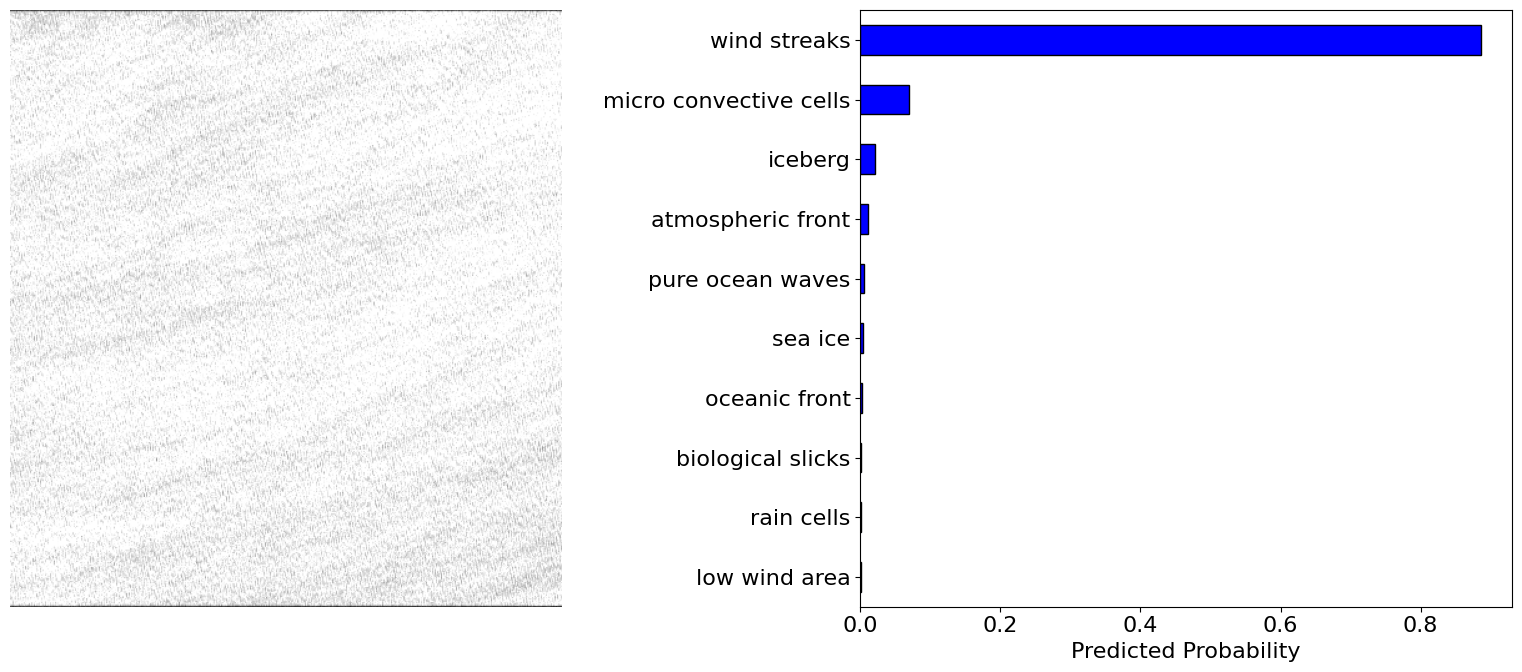

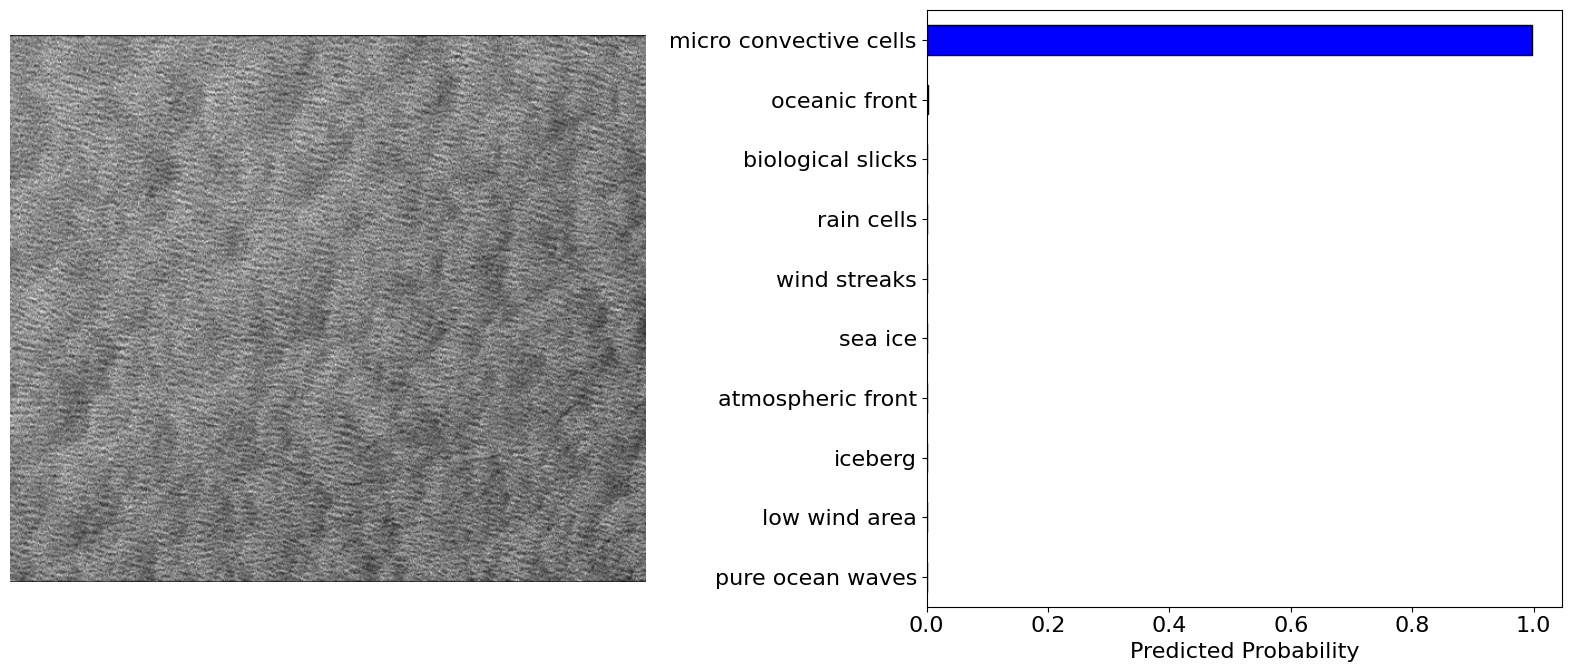

In [ ]:
labels = ["pure ocean waves", "wind streaks","micro convective cells","rain cells","biological slicks",
          "sea ice","iceberg","low wind area","atmospheric front","oceanic front"]
transform = ResizeCenterCropToTensor()

model_path = "./data/experiments/TenGeoP-SARwv/checkpoint.pth.tar"
model.load_model(model_path)

image = image_loader('./data/TenGeoP-SARwv/GeoTIFF/M/s1a-wv1-slc-vv-20160301t151426-20160301t151429-010177-00f045-081.tiff')/100
image = np.asarray(Image.fromarray(image).convert('RGB'))
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/TenGeoP-SARwv/GeoTIFF/G/s1a-wv2-slc-vv-20160813t121619-20160813t121622-012581-013b7b-074.tiff')/100
image = np.asarray(Image.fromarray(image).convert('RGB'))
fig = model.predict_image(image, labels, transform)

image = image_loader('./data/TenGeoP-SARwv/GeoTIFF/H/s1a-wv1-slc-vv-20160918t082043-20160918t082046-013104-014cc7-019.tiff')/100
image = np.asarray(Image.fromarray(image).convert('RGB'))
fig = model.predict_image(image, labels, transform)